# 02 · Train: models, baselines and their cost

This notebook trains or loads every model in Sections 4 and 5, re-runs the baselines on validation, and reproduces
the cost analysis in Section 6.4. The test split is not touched here: it is evaluated once, in `03_evaluate`.

**Modes.** Set the flag in the next cell:

- `RETRAIN = False` (default) loads the training logs committed in `results/runs/` and plots them. On a GPU runtime it
  also builds the CLIP text-feature cache and checks it. This takes about 5 minutes on a T4, or 3 minutes without a
  GPU.
- `RETRAIN = True` trains all six runs from scratch: about 70 minutes on a Colab T4. The new logs go to
  `models/retrained/`, so the committed ones are not overwritten. GPU training is not bit-exact (Section 6.5), so
  the numbers will be close to, but not identical to, the report's.

| Section | Backs report section |
|---|---|
| 1. Data bundle | 3, 6.3 |
| 2. CLIP text-feature cache and its check | 4.3, 4.4, 6.3 |
| 3. The six runs: configuration, training, logs | 4.7, 4.8, 5, 6.4 (Table 6.3) |
| 4. Thresholds and pre-test checks on validation | 4.8, 7 (protocol) |
| 5. Baselines on validation | 5.1, 5.3 |
| 6. Computational and memory cost | 6.4 (Table 6.2, peak memory) |

**Runtime:** use a GPU runtime (Runtime → Change runtime type → T4 GPU). Without a GPU, sections 2 and 6's memory
measurement are skipped and the rest runs on CPU.

In [1]:
RETRAIN = False  # True: train all six runs again (~70 min on a T4)

## Setup

Runs in a fresh Colab runtime or locally from a clone of the repository.

**On Colab**, this cell does three things:

1. It gets the code: it clones the repository at the submission tag, or unpacks the code zip if `CODE_ZIP` is set
   (for when the repository is not public).
2. It installs the few packages Colab lacks, pinned in `requirements-colab.txt`. Colab's own torch, NumPy and pandas
   are kept, and their versions are printed below.
3. It puts the code on the import path.

**Locally**, the cell only finds the repository root. Install with `uv sync` first.

In [2]:
REPO_URL = 'https://github.com/upretisaurav/doc-verify.git'
TAG = 'v1.0-submission'
CODE_ZIP = None  # if the repository is not public: path to the submitted code zip, e.g. '/content/doc-verify.zip'

import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    ROOT = Path('/content/doc-verify')
    if not ROOT.exists():
        if CODE_ZIP:
            subprocess.run(['unzip', '-q', CODE_ZIP, '-d', '/content'], check=True)
        else:
            subprocess.run(['git', 'clone', '-q', '--depth', '1', '--branch', TAG, REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')],
                   check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for path in (ROOT / 'src', ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)

import importlib.metadata
import platform

import torch
import transformers

transformers.logging.set_verbosity_error()  # hide checkpoint-loading reports
transformers.logging.disable_progress_bar()

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
print(f'Python {platform.python_version()} | torch {torch.__version__} | GPU: {gpu}')
print({p: importlib.metadata.version(p) for p in ('timm', 'transformers', 'scikit-learn', 'numpy', 'pandas')})

Python 3.12.8 | torch 2.14.1 | GPU: none
{'timm': '1.0.30', 'transformers': '5.18.0', 'scikit-learn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.6'}


## 1. Data bundle

Training uses the **data bundle**, a 66 MB archive made by `scripts/prepare_colab.py`. It holds every page resized to
224 × 224 (the model's input; Section 4.2), every page's OCR text, and both manifests. It is downloaded from the
repository's GitHub release.

Rebuilding the data from scratch is `01_data`'s job. Here the pages are loaded through the same masked page table as
in training (`doc_verify.data.load_pages`):

- Tobacco3482 pages carry a type label only;
- SAD-Syn pages carry authenticity and kind labels only;
- the test split stays locked out of this notebook.

In [3]:
import pandas as pd

from doc_verify.assets import fetch_bundle
from doc_verify.config import MODELS_DIR, RESULTS_DIR
from doc_verify.data import all_pages, load_pages

bundle = fetch_bundle()
pages = load_pages(('train', 'val'), bundle)
pages.groupby(['source', 'split']).size().unstack()

split,train,val
source,,
sad_syn,2100,450
tobacco3482,2439,522


## 2. CLIP text-feature cache

The CLIP text encoder is frozen (Section 4.4), so its outputs are computed once for every page:

- 8 overlapping windows of 75 tokens, stride 50 (`doc_verify.windows.window_ids`);
- the per-token outputs of every window, stored as float16 in a memory-mapped file of 6,482 × 8 × 77 × 512 values
  (4.1 GB);
- each window's token mask, stored alongside.

Training then reads a page's features by its row number.

`checks.cache_check` then verifies the cache:

- every page's cached mask equals the mask recomputed from its own text;
- for 10 sampled pages, the recomputed features are compared with the cached row and, as a control, with the next
  page's row. The cached row should match closely; the neighbour's row should not.

This needs a GPU. Without one, it is skipped unless `RETRAIN` is set.

In [4]:
import torch

from doc_verify.config import DATA_DIR
from doc_verify.windows import TEXT_WINDOWS, cache_text_features

CACHE = str(DATA_DIR / 'clip_text')
BUILD_CACHE = torch.cuda.is_available() or RETRAIN
if BUILD_CACHE:
    every_page = all_pages(bundle)  # the cache covers all 6,482 pages, in manifest order
    if not Path(f'{CACHE}_features.npy').exists():
        texts = [(bundle / p.source / p.text_path).read_text(encoding='utf-8') for p in every_page.itertuples()]
        cache_text_features(texts, CACHE, TEXT_WINDOWS)
    from doc_verify.checks import cache_check
    print(cache_check(every_page, bundle, CACHE))
else:
    print('No GPU: cache not built (not needed unless RETRAIN = True).')

No GPU: cache not built (not needed unless RETRAIN = True).


## 3. The six runs

Each run is one `TrainConfig`. Anything not listed in the table takes the default, all fixed in advance (Section 4.8):

- AdamW with weight decay 0.05;
- learning rate 2 × 10⁻⁵ for the pretrained backbone and 10⁻⁴ for the new layers;
- cosine schedule, batch size 32, seed 42;
- 15 epochs with early stopping after 3 epochs without improvement in the validation selection score.

The runs are:

- **Main model and its ablation:** `fused` and `fused_no_kind` (λ₂ = 0).
- **Learned baselines:** `image_vit` and `resnet18` (Section 5.1).
- **Diagnostics:** the two authenticity-only runs, reported on validation only (Section 5.4).

In [5]:
import json
from dataclasses import asdict

from doc_verify.train import TrainConfig

RUNS = {
    'fused': TrainConfig(model='fused'),
    'fused_no_kind': TrainConfig(model='fused', lambda_kind=0),
    'image_vit': TrainConfig(model='image_vit'),
    'resnet18': TrainConfig(model='resnet18', lambda_auth=0, lambda_kind=0, lr_backbone=1e-3, lr_head=1e-3,
                            epochs=30, patience=5),
    'fused_auth_only': TrainConfig(model='fused', use_type=False, epochs=40, patience=10),
    'fused_auth_long': TrainConfig(model='fused', use_type=False, epochs=40, patience=40),
}
for run, config in RUNS.items():  # the configs committed with each run's logs must be these
    committed = json.loads((RESULTS_DIR / 'runs' / run / 'config.json').read_text())
    assert committed == {**asdict(config), 'num_workers': committed['num_workers']}, run
pd.DataFrame({run: asdict(config) for run, config in RUNS.items()}).T.drop(columns=['num_workers', 'pretrained'])

,model,lambda_auth,lambda_kind,use_type,epochs,patience,batch_size,lr_backbone,lr_head,weight_decay,seed
fused,fused,1.0,1.0,True,15,3,32,0.00002,0.0001,0.05,42
fused_no_kind,fused,1.0,0,True,15,3,32,0.00002,0.0001,0.05,42
image_vit,image_vit,1.0,1.0,True,15,3,32,0.00002,0.0001,0.05,42
resnet18,resnet18,0,0,True,30,5,32,0.001,0.001,0.05,42
fused_auth_only,fused,1.0,1.0,False,40,10,32,0.00002,0.0001,0.05,42
fused_auth_long,fused,1.0,1.0,False,40,40,32,0.00002,0.0001,0.05,42


**Training or loading the logs.**

- **With `RETRAIN = True`:** each run is trained with `doc_verify.train.train`. After every epoch it predicts the
  validation split, computes the selection score, saves the best checkpoint, and stops early when the score has not
  improved for `patience` epochs.
- **Otherwise:** the committed logs are loaded.

Either way, the curves below show how each run trained.

In [6]:
from doc_verify.train import train

if RETRAIN:
    LOGS = MODELS_DIR / 'retrained'
    for run, config in RUNS.items():
        if not (LOGS / run / 'best_metrics.json').exists():
            train(config, LOGS / run, data_root=bundle, text_cache=CACHE)
else:
    LOGS = RESULTS_DIR / 'runs'
histories = {run: pd.read_csv(LOGS / run / 'history.csv') for run in RUNS}
summary = pd.DataFrame({run: {'epochs run': len(h), 'best epoch': int(h.val_selection.idxmax()) + 1,
                              'best val selection score': h.val_selection.max()}
                        for run, h in histories.items()}).T
summary

,epochs run,best epoch,best val selection score
fused,11.0,8.0,0.687068
fused_no_kind,8.0,5.0,0.694322
image_vit,13.0,10.0,0.672220
resnet18,12.0,7.0,0.543952
fused_auth_only,14.0,4.0,0.551378
fused_auth_long,40.0,4.0,0.548316


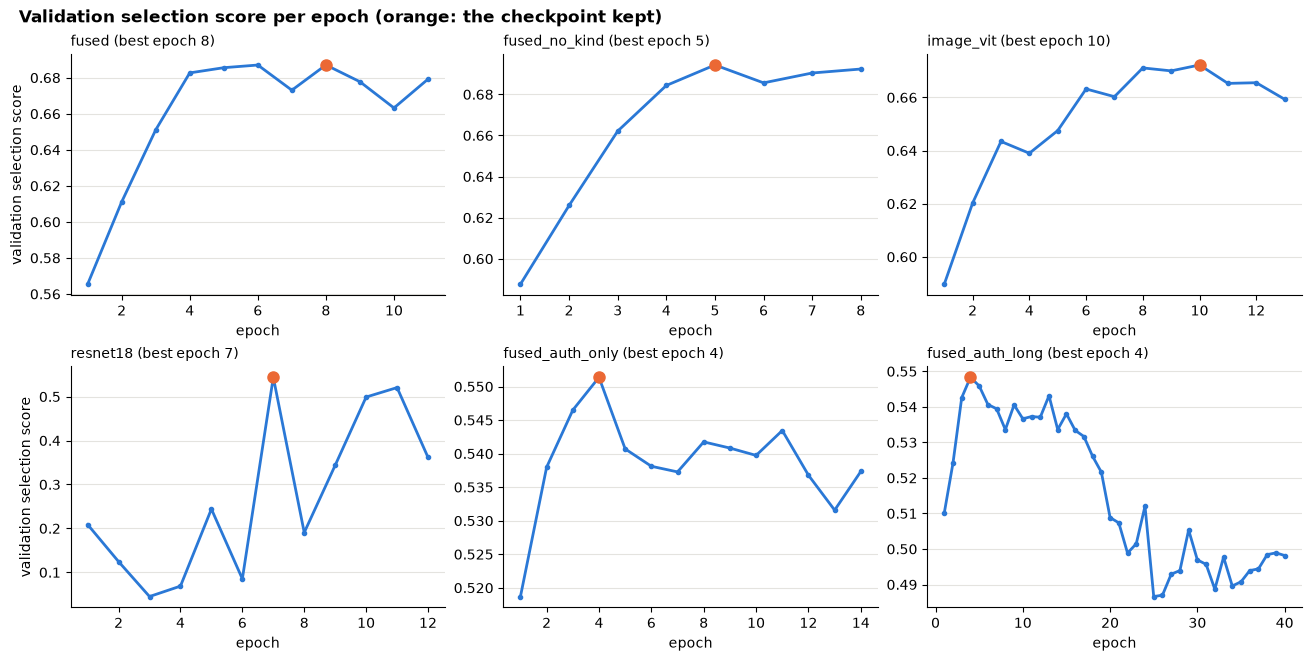

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=False, constrained_layout=True)
for ax, (run, h) in zip(axes.flat, histories.items()):
    ax.plot(h.epoch, h.val_selection, color='#2a78d6', linewidth=2, marker='o', markersize=3)
    best = h.val_selection.idxmax()
    ax.plot(h.epoch[best], h.val_selection[best], 'o', color='#eb6834', markersize=8)
    ax.set_title(f'{run} (best epoch {best + 1})', loc='left', fontsize=10)
    ax.set_xlabel('epoch')
    ax.grid(axis='y', color='#e4e3df')
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel('validation selection score')
fig.suptitle('Validation selection score per epoch (orange: the checkpoint kept)', x=0.01, ha='left',
             fontweight='bold')
plt.show()

## 4. Thresholds and pre-test checks (validation)

Accuracy and F1 for authenticity need a decision threshold. For each model it is chosen on the validation predictions
to maximise balanced accuracy (`evaluate.choose_threshold`), then frozen in `reports/val_thresholds.json` before the
test split was opened. Recomputing the thresholds here must give the frozen values.

`checks.predictions_check` confirms that every saved validation prediction carries the labels of the page it claims
to be. This guards against misaligned rows.

In [8]:
import numpy as np

from doc_verify.checks import predictions_check
from doc_verify.data import MISSING
from doc_verify.evaluate import choose_threshold

frozen = json.loads((ROOT / 'reports' / 'val_thresholds.json').read_text())
val_files = {run: LOGS / run / 'val_predictions.csv' for run in ('fused', 'fused_no_kind', 'image_vit')}
val_files |= {name: RESULTS_DIR / 'val_predictions' / f'{name}.csv' for name in ('tfidf', 'rule_checker')}
for name, path in val_files.items():
    val = pd.read_csv(path)
    authed = val[val.auth_label != MISSING]
    threshold = choose_threshold(authed.auth_label, authed.auth_score)
    print(f'{name:14s} threshold {threshold:.4f} (frozen {frozen[name]:.4f})', predictions_check(val, pages))
    if not RETRAIN:
        assert np.isclose(threshold, frozen[name]), name

fused          threshold 0.3989 (frozen 0.3989) {'rows': 972, 'matched': 972, 'label_disagreements': 0}
fused_no_kind  threshold 0.4847 (frozen 0.4847) {'rows': 972, 'matched': 972, 'label_disagreements': 0}


image_vit      threshold 0.6996 (frozen 0.6996) {'rows': 972, 'matched': 972, 'label_disagreements': 0}
tfidf          threshold 0.3937 (frozen 0.3937) {'rows': 972, 'matched': 972, 'label_disagreements': 0}
rule_checker   threshold 1.0000 (frozen 1.0000) {'rows': 450, 'matched': 450, 'label_disagreements': 0}


## 5. Baselines on validation

These are fast, so they are always re-run, from the bundle's OCR text and images:

- **TF-IDF + logistic regression:** one model per task, each fitted only on the training pages that carry that task's
  label.
- **CLIP zero-shot:** document type from the page image and ten prompts.
- **The rule checker:** value extraction from OCR text, then the document type's consistency rules.

Each result is compared with the predictions saved when the baselines were first run. All three should match.
CLIP's predictions can differ on a page or two between CPU and GPU, from floating-point rounding.

In [9]:
from doc_verify.baselines import clip_zero_shot, tfidf_baseline
from doc_verify.data import KIND_CLASSES
from doc_verify.evaluate import head_metrics
from doc_verify.rule_checker import rule_checker_predictions

train_pages, val_pages = pages[pages.split == 'train'], pages[pages.split == 'val']
saved = {name: pd.read_csv(RESULTS_DIR / 'val_predictions' / f'{name}.csv').set_index('page_index')
         for name in ('tfidf', 'rule_checker', 'clip_zero_shot')}

tfidf = tfidf_baseline(train_pages, val_pages, bundle).set_index('page_index')
rules = rule_checker_predictions(val_pages[val_pages.source == 'sad_syn'], bundle / 'sad_syn').set_index('page_index')
rules['kind_pred'] = rules.kind_name.map({name: i for i, name in enumerate(KIND_CLASSES)})
rules['type_label'] = MISSING
device = 'cuda' if torch.cuda.is_available() else 'cpu'
clip = clip_zero_shot(val_pages[val_pages.source == 'tobacco3482'], bundle, device=device).set_index('page_index')

print('TF-IDF: identical predictions on', f"{(tfidf.type_pred == saved['tfidf'].type_pred).mean():.1%}",
      'of pages; largest authenticity-score difference',
      f"{(tfidf.auth_score - saved['tfidf'].auth_score).abs().max():.2g}")
print('Rule checker: identical scores on', f"{(rules.auth_score == saved['rule_checker'].auth_score).mean():.1%}",
      'of pages')
print('CLIP zero-shot: identical predictions on',
      f"{(clip.type_pred == saved['clip_zero_shot'].type_pred).mean():.1%} of pages")
pd.DataFrame({'TF-IDF + LR': head_metrics(tfidf.reset_index()), 'Rule checker': head_metrics(rules.reset_index()),
              'CLIP zero-shot': head_metrics(clip.reset_index())}).T.round(3)

TF-IDF: identical predictions on 100.0% of pages; largest authenticity-score difference 5.6e-17
Rule checker: identical scores on 100.0% of pages
CLIP zero-shot: identical predictions on 100.0% of pages


,type_accuracy,type_macro_f1,auth_auc,auth_accuracy,auth_macro_f1,kind_macro_f1
TF-IDF + LR,0.747,0.706,0.485,0.498,0.497,0.133
Rule checker,NaN,NaN,0.758,0.753,0.753,0.662
CLIP zero-shot,0.418,0.433,NaN,NaN,NaN,NaN


## 6. Computational and memory cost (Section 6.4)

**Parameters and FLOPs.** Parameters are counted directly. FLOPs are counted for one page, forward pass, with
`torch.utils.flop_counter.FlopCounterMode`, which counts a multiply–add as two FLOPs.

The counter does not see fused attention kernels, so they are switched off for the count (Section 6.5):

- the fusion module is put in training mode;
- the ViT's fused attention is disabled;
- CLIP is loaded with eager attention.

No pretrained weights are needed for counting.

In [10]:
from torch.utils.flop_counter import FlopCounterMode
from transformers import CLIPTextModel

from doc_verify.models import FusionModel, ResNet18Scratch
from doc_verify.text_length import CLIP_MODEL


def gflops(fn):
    with FlopCounterMode(display=False) as counter, torch.no_grad():
        fn()
    return counter.get_total_flops() / 1e9


def n_params(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


image = torch.rand(1, 3, 224, 224)
fused = FusionModel(pretrained=False).train()
for block in fused.image_encoder.vit.blocks:
    block.attn.fused_attn = False
patches = fused.image_encoder(image).detach()
resnet = ResNet18Scratch()
clip_text = CLIPTextModel.from_pretrained(CLIP_MODEL, attn_implementation='eager').eval()


def fusion_gflops(windows):
    text, mask = torch.randn(1, windows, 77, 512), torch.ones(1, windows, 77, dtype=torch.long)
    fused.fusion.window_embedding = torch.nn.Embedding(max(windows, TEXT_WINDOWS), 512)
    return gflops(lambda: fused.fusion(patches, text, mask))


cost = pd.DataFrame([
    {'component': 'ViT-B/16 image encoder', 'params (M)': n_params(fused.image_encoder),
     'GFLOPs per page': gflops(lambda: fused.image_encoder(image))},
    {'component': 'CLIP text encoder (frozen, run once)', 'params (M)': n_params(clip_text),
     'GFLOPs per page': gflops(lambda: clip_text(input_ids=torch.randint(0, 49000, (TEXT_WINDOWS, 77))))},
    {'component': 'Fusion, 8 windows', 'params (M)': n_params(fused.fusion), 'GFLOPs per page': fusion_gflops(8)},
    {'component': 'Heads', 'params (M)': n_params(fused.heads), 'GFLOPs per page': 0.0},
    {'component': 'ResNet18', 'params (M)': n_params(resnet), 'GFLOPs per page': gflops(lambda: resnet(image))},
]).set_index('component')
display(cost.round(3))
pd.Series({w: fusion_gflops(w) for w in (1, 2, 4, 8, 16)}, name='fusion GFLOPs per page').rename_axis('windows').round(1)

,params (M),GFLOPs per page
component,,
ViT-B/16 image encoder,85.799,35.126
"CLIP text encoder (frozen, run once)",63.166,47.672
"Fusion, 8 windows",9.070,12.006
Heads,0.008,0.000
ResNet18,11.185,3.627


windows
1      1.8
2      3.1
4      5.9
8     12.0
16    26.5
Name: fusion GFLOPs per page, dtype: float64

**Peak GPU memory** for training: three steps of each model at batch size 32 with fp16 mixed precision, the training
settings, measured with `torch.cuda.max_memory_allocated()`. Report values on a T4: fused 4.93 GB, image-only ViT
3.49 GB, ResNet18 1.12 GB.

In [11]:
from torch.utils.data import DataLoader

from doc_verify.data import PageDataset
from doc_verify.models import MODELS
from doc_verify.train import forward, masked_losses, run_pages

if torch.cuda.is_available():
    train_only = pages[pages.split == 'train']
    for run in ('fused', 'image_vit', 'resnet18'):
        config = RUNS[run]
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        model = MODELS[config.model](pretrained=False).cuda()
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
        scaler = torch.amp.GradScaler('cuda')
        dataset = PageDataset(run_pages(train_only, config), bundle, CACHE if config.model == 'fused' else None)
        for step, batch in enumerate(DataLoader(dataset, batch_size=32, shuffle=True)):
            batch = {k: v.cuda() if k.endswith('label') else v for k, v in batch.items()}
            with torch.autocast('cuda', dtype=torch.float16):
                loss = masked_losses(forward(model, batch, 'cuda'), batch, config)['total']
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            if step == 2:
                break
        print(f'{run}: {torch.cuda.max_memory_allocated() / 2**30:.2f} GB')
        del model, optimizer
else:
    print('No GPU: peak memory not measured here.')

No GPU: peak memory not measured here.


**Training time** (Table 6.3) was measured on a Colab T4 from each run's log timestamps, with the validation pass
included:

| Run | Time per epoch |
|---|---|
| Fused | 74 s |
| Fused, λ₂ = 0 | 74 s |
| Image-only ViT | 47 s |
| ResNet18 | 7 s |
| Fused, authenticity only | 37 s |
| Fused, authenticity only, 40 epochs | 37 s |

All six runs total about 68 minutes. With `RETRAIN = True`, the time each run takes is shown by the training cell
above.